##Neural-SIR with Stochastic DE

To incorporate stochastic noise into our SIR differential equations, following the ideas from "Modeling Infectious Disease" by Matt J. Keeling and Pejman Rohani, we will simulate a system with both deterministic and stochastic components.

In epidemiological models, stochastic noise is often introduced to represent the random fluctuations in transmission rates, recovery rates, or even the number of individuals moving between compartments due to uncertainties and random effects.

1. **Stochastic Differential Equations (SDEs)**:
   The stochastic version of the SIR model modifies the deterministic equations by adding noise terms to capture random effects. Typically, this is modeled by adding a random Wiener process (a continuous-time stochastic process) or Poisson noise.

2. **Introducing Noise to the SIR Equations**:
   We will modify the basic deterministic SIR model by adding stochastic terms to the equations that affect the infection and recovery rates, using multiplicative noise.

   ### Deterministic SIR Equations:

$
\frac{dS_h}{dt} = -\beta \cdot \frac{S_h \cdot I_h}{N_h}
$

$
\frac{dI_h}{dt} = \beta \cdot \frac{S_h \cdot I_h}{N_h} - \gamma \cdot I_h
$

$
\frac{dR_h}{dt} = \gamma \cdot I_h
$

### Stochastic SIR Equations:

To add stochasticity, we include random noise terms for infection and recovery rates. These noise terms represent the random variation (fluctuations) in the infection and recovery processes.

$
dS_h = \left(-\beta \cdot \frac{S_h \cdot I_h}{N_h}\right) \cdot dt + \sigma_S \cdot S_h \cdot dW_s
$

$
dI_h = \left(\beta \cdot \frac{S_h \cdot I_h}{N_h} - \gamma \cdot I_h\right) \cdot dt + \sigma_I \cdot I_h \cdot dW_I
$

$
dR_h = \left(\gamma \cdot I_h\right) \cdot dt
$

The differential equations (DE) represented in the code are based on the **Stochastic SIR Model** with additional noise components (Wiener processes) introduced for the susceptible ($ S_h $) and infected ($ I_h $) compartments. This introduces randomness into the infection and recovery dynamics, making it a stochastic version of the standard SIR model.



### Implementing a Stochastic SIR Model in Python:


### Stochastic Nature of the Model:
The random fluctuations (Wiener processes $ dW_S $ and $ dW_I $) make the dynamics **non-deterministic**, meaning each time we run the simulation, the outcome will differ. This is a more realistic representation of real-world epidemics, where random events (e.g., superspreaders, random recoveries) can influence the trajectory of the outbreak.



In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import odeint
import random
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import load_model, Model
from sklearn.metrics import r2_score
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
from tensorflow.keras.callbacks import Callback

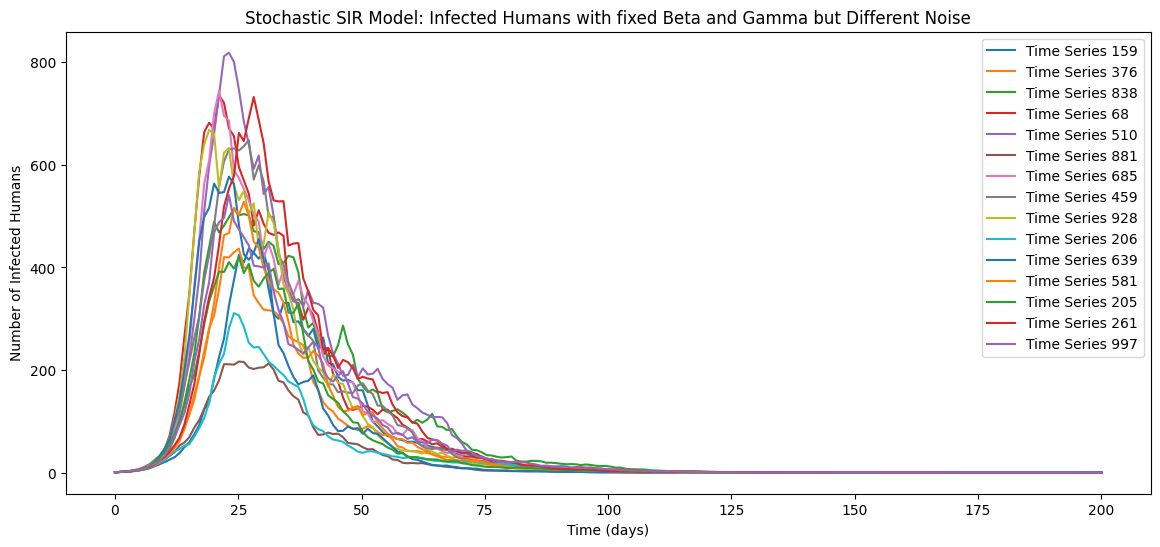

In [ ]:
# SIR model with stochastic noise for human population
def stochastic_sir_model(y, t, N_h, beta, gamma, sigma_S, sigma_I, dt):
    S_h, I_h, R_h = y

    # Random fluctuations (Wiener processes)
    dW_S = np.random.normal(0, np.sqrt(dt))  # Wiener process for S_h
    dW_I = np.random.normal(0, np.sqrt(dt))  # Wiener process for I_h

    # Stochastic SIR equations with noise
    dS_h_dt = (-beta * S_h * I_h / N_h) + sigma_S *S_h* dW_S
    dI_h_dt = (beta * S_h * I_h / N_h - gamma * I_h) + sigma_I * I_h* dW_I
    dR_h_dt = gamma * I_h

    return [dS_h_dt, dI_h_dt, dR_h_dt]

# Parameters
N_h = 1000 # Total human population
sigma_S = 0.5 # Noise in susceptible
sigma_I = 0.5 # Noise in infected
dt = 0.02 # Time step for noise

# Constant parameters for beta and gamma
beta = 0.5  # Fixed transmission rate
gamma = 1/14 # Fixed recovery rate (e.g., 14-day recovery)

# Initial conditions for SIR model
S_h0 = N_h - 1   # Initial susceptible humans
I_h0 = 1         # Initial infected humans
R_h0 = 0         # Initial recovered humans
y0 = [S_h0, I_h0, R_h0]  # Initial condition vector

# Time points (e.g., 200 days)
t = np.linspace(0, 200, 200 )

# Store the results for infected humans over time (for 100 random time series)
infected_time_series = []

# Simulate 1000 time series with fixed beta and gamma but different noise
for _ in range(1000):  # Generate 1000 random time series
    S_h, I_h, R_h = [S_h0], [I_h0], [R_h0]  # Reset the initial conditions
    for i in range(1, len(t)):
        y = [S_h[-1], I_h[-1], R_h[-1]]  # Current values of S_h, I_h, R_h
        dS_h, dI_h, dR_h = stochastic_sir_model(y, t[i], N_h, beta, gamma, sigma_S, sigma_I, dt)

        # Update S_h, I_h, and R_h with stochastic noise
        S_h.append(max(0,S_h[-1] + dS_h))
        I_h.append(max(0,I_h[-1] + dI_h))
        R_h.append(max(0,R_h[-1] + dR_h))

    infected_time_series.append(I_h)  # Append the infected time series

# Plotting the infected humans over time for 15 random time series with the same beta and gamma
plt.figure(figsize=(14, 6))
for i in random.sample(range(1000), 15):  # Plot all 15 time series
    plt.plot(t, infected_time_series[i], label=f'Time Series {i+1}')
plt.xlabel('Time (days)')
plt.ylabel('Number of Infected Humans')
plt.title('Stochastic SIR Model: Infected Humans with fixed Beta and Gamma but Different Noise')
plt.legend()
plt.show()

In a true Wiener process, the noise is generally additive and independent of the system state, as in the case of standard Brownian motion.

However, in our case, we're using multiplicative noise, which is a form of stochastic differential equation (SDE) often referred to as **multiplicative noise-driven dynamics**. This type of noise can model situations where the fluctuations depend on the population sizes \(S(t)\) and \(I(t)\).

In summary:

- **Wiener process:** Typically used to describe **additive** noise, where fluctuations are independent of the current state of the system.
- **Multiplicative noise (our case):** The noise is proportional to the values of \(S(t)\) and \(I(t)\), meaning the noise grows or shrinks with the size of the populations.

###Stochastic DE for Neural-SIR

   - $ dS(t) = - \beta \cdot S(t) \cdot I(t)/N \cdot dt + \sigma_S \cdot S(t) \cdot dW_I(t) $
   - $ dI(t) = \beta \cdot S(t) \cdot I(t)/N \cdot dt - \gamma \cdot I(t) \cdot dt + \sigma_I \cdot I(t) \cdot dW_2(t) $
   - $ dR(t) = \gamma \cdot I(t) \cdot dt $

   Here:
   - $ dW_s(t), dW_I(t) $ are Wiener processes (stochastic terms).
   - $ \sigma_S, \sigma_I $ represent the intensity of the noise for each compartment.

- **Infection Term** $ - \beta \frac{S_h I_h}{N_h} $: This is the standard infection term from the SIR model, where the susceptible population ($ S_h $) becomes infected based on the interaction between susceptible and infected individuals, modulated by the transmission rate $ \beta $.
  
- **Noise in Susceptibles** $ + \sigma_S S_h \, dW_S $: This adds stochastic noise to the susceptible population dynamics. The noise intensity $ \sigma_S $ scales the fluctuation, and the $ dW_S $ term represents a Wiener process that introduces random variability into the dynamics of $ S_h $.

- **Infected Population Dynamics** $ \beta \frac{S_h I_h}{N_h} - \gamma I_h $: The infected population changes based on new infections (same term as above) minus recoveries, which happen at a rate $ \gamma $.

- **Noise in Infected** $ + \sigma_I I_h \, dW_I $: Similarly, the infected population also experiences random fluctuations based on the Wiener process $ dW_I $, with intensity $ \sigma_I $.

- **Recovery Term** $ \gamma I_h $: This is the standard recovery term, where individuals recover from infection at the rate $ \gamma $.



### Saving Combined Time Series to CSV

In [ ]:
# We use the generated transmission rates as beta and recovery rates as gamma values
# beta_values = transmission_rates
# gamma_values = recovery_rates

# Combining the time-series data into a single DataFrame
combined_data = infected_time_series

# Including both Beta and Gamma in the column names
combined_df = pd.DataFrame(np.array(combined_data).T)

# Adding a column for time
combined_df['Time (days)'] = t

#Saving the combined data to CSV for future use
combined_df.to_csv('combined_sir_infected_time_series.csv', index=False)

print('Generated time-series data saved to combined_sir_infected_time_series.csv')
print('Shape of the data:', combined_df.shape)
print(combined_df.head())


Generated time-series data saved to combined_sir_infected_time_series.csv
Shape of the data: (200, 1001)
          0         1         2         3         4         5         6  \
0  1.000000  1.000000  1.000000  1.000000  1.000000  1.000000  1.000000   
1  1.406241  1.469619  1.494875  1.570197  1.471369  1.397893  1.449696   
2  2.010968  2.330385  1.998436  2.431422  2.011745  1.809255  2.072176   
3  2.882382  3.346639  2.849141  3.491897  2.973905  2.794689  3.034930   
4  4.236298  5.164638  4.036134  5.153038  3.853495  3.788786  4.629256   

          7         8         9  ...       991       992       993       994  \
0  1.000000  1.000000  1.000000  ...  1.000000  1.000000  1.000000  1.000000   
1  1.462686  1.380983  1.441226  ...  1.463373  1.380033  1.496903  1.416961   
2  1.926734  1.799798  1.979467  ...  2.208214  1.994870  1.929495  1.789334   
3  3.050767  2.670003  2.649559  ...  3.043096  2.949738  2.410878  2.656003   
4  4.479864  3.875971  3.744891  ...  4.2767

### Loading the Data and Splitting it into Training and Testing

In [ ]:
# Loading the combined data (100 infection rate time series, 200 time steps)
csv_file = 'combined_sir_infected_time_series.csv'
data = pd.read_csv(csv_file)

# Extracting the time-series data (excluding the 'Time (days)' column)
time_series_data = data.drop(columns=['Time (days)']).values  # Shape: (200, 100)

# Spliting the data into training (70 time-series) and testing (30 unseen time-series)
train_size = int(time_series_data.shape[1] * 0.7)  # 70% of the columns for training and the rest for testing

train_data = time_series_data[:, :train_size]  # Shape: (200, 70)
test_data = time_series_data[:, train_size:]   # Shape: (200, 30)

print('Training data:', train_data.shape)
print('Testing data:', test_data.shape)

Training data: (200, 700)
Testing data: (200, 300)


### Normalise the Data

In [ ]:
# Normalising each time-series independently for both training and testing data
scalers = {}  # To store scalers for each series

# For each time-series in the training set
train_data_scaled = np.zeros_like(train_data)
for i in range(train_data.shape[1]):  # Loop through each time-series (column)
    scalers[i] = MinMaxScaler(feature_range=(0, 1))  # Create a new scaler for each time-series
    train_data_scaled[:, i] = scalers[i].fit_transform(train_data[:, i].reshape(-1, 1)).flatten()  # Scale each series independently

# Similarly for the test set
test_data_scaled = np.zeros_like(test_data)
for i in range(test_data.shape[1]):  # Loop through each time-series (column)
    test_data_scaled[:, i] = scalers[i].transform(test_data[:, i].reshape(-1, 1)).flatten()  # Scale using the same scaler as for training

### Building the LSTM-SIR models

Building LSTM-SIR with differents layers (1, 2, 3 and 4), 100 hidden units each, and two different epochs ( 10 & 20).

* Layers_list = [1, 2, 3, 4]
* Hidden units_list = [50,100]
* Epochs_list = [10, 20]

### Defining the function to create directories for each model

In [ ]:
# Function to create directories for each model
def create_model_directory(model_name):
    if not os.path.exists(model_name):
        os.makedirs(model_name)

# Function to save the training and validation loss plot
def save_loss_plot(history, model_name):
    plt.figure(figsize=(8, 6))
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f'{model_name}: Training and Validation Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.savefig(f'{model_name}/loss_plot_{model_name}.png')
    plt.close()  # Close the plot to save memory

### Defining the function to save model parameters (weights and biases)


We will modify the training process to save the **weights and biases** after each epoch using **Keras Callbacks**.

The **ModelCheckpoint** callback can be used to save the weights, and we will create a custom callback to calculate and save the parameters (weights and biases) as follows:

1. Custom Callback to Save Weights and Biases After Each Epoch:
We will define a custom callback to save weights and biases in the format you specified. This will save them in .csv files after each epoch.

2. Modify the Model Training Process:
We will integrate this callback into the model training process so that the weights and biases are saved after each epoch.

To calculate the number of weights and biases, we will use the **model.count_params()** function for each layer in the model.

In [ ]:
# Function to save model parameters (weights and biases)
def save_model_parameters(model, model_name,epoch):
    # Get the weights of the model
    weights = model.get_weights()

    # Create a directory for the model parameters if it doesn't exist
    params_dir = f'{model_name}/parameters_epoch_{epoch}'
    if not os.path.exists(params_dir):
        os.makedirs(params_dir)

    # Save each weight matrix and bias vector
    for i, weight in enumerate(weights):
        # Save each parameter array (weights or biases) to a separate file
        np.savetxt(f'{params_dir}/param_{i}.csv', weight, delimiter=',')

    print(f"Model parameters saved for {model_name} at epoch {epoch}.")

We will add:

1. Custom Callback **SaveModelParamsCallback**:

* This callback saves the model's weights and biases in .csv format after each epoch in the directory structure you prefer.
* It calls **save_model_parameters()** after every epoch during training.

2. Count Model Parameters:

* The **count_model_params()** function is added to calculate and return the total, trainable, and non-trainable parameters for each model.

3. Logging Parameters:

* The results of each model now include the number of total, trainable, and non-trainable parameters, which are saved to the experiment results.

In [ ]:
#Custom callback to save weights and biases after each epoch
class SaveModelParamsCallback(Callback):
    def __init__(self, model_name):
        super(SaveModelParamsCallback, self).__init__()
        self.model_name = model_name

    def on_epoch_end(self, epoch, logs=None):
        # Save model parameters at the end of each epoch
        save_model_parameters(self.model, self.model_name, epoch + 1)  # Epoch index starts from 0

# Function to count the number of weights and biases in the model
def count_model_params(model):
    total_params = model.count_params()  # Total parameters (weights + biases)
    trainable_params = np.sum([np.prod(v.shape) for v in model.trainable_weights])
    non_trainable_params = np.sum([np.prod(v.shape) for v in model.non_trainable_weights])

    return total_params, trainable_params, non_trainable_params

### Defining the function to save MAE, RMSE and R2 for each model

In [ ]:
# Function to save MAE, RMSE and R2 for each model
def save_mae_rmse(mae, rmse,r2, model_name):
    with open(f'{model_name}/mae_rmse_r2.txt', 'w') as f:
        f.write(f'MAE: {mae}\n')
        f.write(f'RMSE: {rmse}\n')
        f.write(f'R²: {r2}\n')  # Added R² to the results

# Define a function to save scatter plot for actual vs predicted values
def save_scatter_plot(actual, predicted, model_name, series_num):
    plt.figure(figsize=(6, 6))
    plt.scatter(actual, predicted, c='blue', marker='o')
    plt.plot([min(actual), max(actual)], [min(actual), max(actual)], color='red', linewidth=2)
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.title(f'Actual vs Predicted for {model_name} - Series {series_num}')
    plt.savefig(f'{model_name}/scatter_plot_series_{series_num}.png')
    plt.close()

# Defining the LSTM-SIR model with a learning rate = 0.0001

In [ ]:
from tensorflow.keras.layers import Dropout

# Build the LSTM-SIR model with a learning rate = 0.0001
def build_lstm_model(layers=1, units=100, look_back=10,learning_rate=0.0001, dropout_rate=0.2):
    model = Sequential()
    model.add(LSTM(units, return_sequences=(layers > 1), input_shape=(look_back, 1)))  # Input for one time-series
    model.add(Dropout(dropout_rate))  # Dropout after the first LSTM layer

    # Additional LSTM layers with Dropout
    for _ in range(1, layers):
        model.add(LSTM(units, return_sequences=(_ != layers - 1)))
        model.add(Dropout(dropout_rate))  # Dropout after each LSTM layer

    # Final Dense layer for output
    model.add(Dense(1))  # Single output for each time-series

    # Compile the model with a learning rate
    optimizer = Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mean_squared_error')
    return model

def create_sequences(data, look_back):
    X, y = [], []
    for i in range(len(data) - look_back):
        X.append(data[i:i + look_back])
        y.append(data[i + look_back])
    return np.array(X), np.array(y)

# Learning rate scheduler
def lr_schedule(epoch, lr):
    if epoch > 10:
        return lr * 0.5  # Decrease the learning rate after 10 epochs
    return lr

In [ ]:
# The training loop to save models and plots
def run_experiments(train_data_scaled, test_data_scaled, epochs_list, layers_list, units_list, look_back):
    experiment_results = []

    for epochs in epochs_list:
        for layers in layers_list:
            for units in units_list:
                model_name = f'LSTM-SIR-{layers}_layers-{units}_units-{epochs}_epochs'
                print(f"Training model: {model_name}")

                # Create model directory
                create_model_directory(model_name)

                # Build and compile the model
                model = build_lstm_model(layers, units, look_back,learning_rate=0.0001)

                # Count model parameters (weights and biases)
                total_params, trainable_params, non_trainable_params = count_model_params(model)
                print(f"Model {model_name} has {total_params} total parameters.")
                print(f"Trainable parameters: {trainable_params}, Non-trainable parameters: {non_trainable_params}")

                # Prepare X_train and y_train from train_data_scaled
                X_train, y_train = create_sequences(train_data_scaled.flatten(), look_back)
                X_train = X_train.reshape((X_train.shape[0], look_back, 1))  # Reshaping for LSTM

                # Define callbacks
                save_params_callback = SaveModelParamsCallback(model_name)

                # Set up checkpoints and learning rate schedule
                checkpoint = ModelCheckpoint(f'{model_name}/best_model.keras', monitor='val_loss', save_best_only=True)
                lr_scheduler = LearningRateScheduler(lr_schedule)

                # Train the model on the entire training set
                history = model.fit(X_train, y_train, epochs=epochs, batch_size=32, verbose=2, validation_split=0.2,callbacks=[checkpoint, lr_scheduler])

                # Save the trained model
                model.save(f'{model_name}/model_{model_name}.keras')

                # Save the training and validation loss plot
                save_loss_plot(history, model_name)

                # Test the model on the test set and calculate MAE, RMSE, and R²
                mae_list = []
                rmse_list = []
                r2_list = []
                for i in range(test_data.shape[1]):
                    test_series = test_data_scaled[:, i]
                    X_test_i, y_test_i = create_sequences(test_series, look_back)
                    X_test_i = X_test_i.reshape((X_test_i.shape[0], look_back, 1))

                    # Predict
                    predicted_test_i = model.predict(X_test_i)
                    predicted_test_i_inverse = scalers[0].inverse_transform(predicted_test_i.reshape(-1, 1))
                    y_test_i_inverse = scalers[0].inverse_transform(y_test_i.reshape(-1, 1))

                    # Calculate MAE, RMSE, and R² for the test series
                    mae = mean_absolute_error(y_test_i_inverse, predicted_test_i_inverse)
                    rmse = np.sqrt(mean_squared_error(y_test_i_inverse, predicted_test_i_inverse))
                    r2 = r2_score(y_test_i_inverse, predicted_test_i_inverse) # Calculate R² score

                    mae_list.append(mae)
                    rmse_list.append(rmse)
                    r2_list.append(r2)

                    # Save scatter plot for the current test series
                    #save_scatter_plot(y_test_i_inverse, predicted_test_i_inverse, model_name, i+1)

                    # Save model parameters (coefficients) after training on each series
                    #save_model_parameters(model, model_name, i+1)  # Save after each series

                # Calculate average MAE, RMSE, and R² across all test series
                average_mae = np.mean(mae_list)
                average_rmse = np.mean(rmse_list)
                average_r2 = np.mean(r2_list)  # Average R² score

                # Save MAE, RMSE, and R² to a file
                save_mae_rmse(average_mae, average_rmse,average_r2, model_name)

                # Append the results to the experiment results list
                experiment_results.append({
                    'Model': model_name,
                    'Epochs': epochs,
                    'Layers': layers,
                    'Units': units,
                    'MAE': average_mae,
                    'RMSE': average_rmse,
                    'R²': average_r2,  # Add R² to the results
                    'Final_Training_Loss': history.history['loss'][-1],  # Final training loss
                    'Final_Validation_Loss': history.history['val_loss'][-1],  # Final validation loss
                    'Total_Params': total_params,  # Add total params to the results
                    'Trainable_Params': trainable_params,
                    'Non_Trainable_Params': non_trainable_params
                })

    return pd.DataFrame(experiment_results)


In [ ]:
# Define the parameters for the experiments
epochs_list = [ 10, 20]  # List of epochs to experiment with
layers_list = [1, 2, 3,4]  # Number of LSTM layers
units_list = [100]  # Number of hidden units in each LSTM layer

look_back = 10  # Number of time steps to look back in the input data

# Run the experiments
experiment_results = run_experiments(train_data_scaled,
                                     test_data_scaled,
                                     epochs_list,
                                     layers_list,
                                     units_list,
                                     look_back)


# Save the experiment results to a CSV file
experiment_results.to_csv('experiment_results.csv', index=False)

# Print the experiment results
print(experiment_results)

Training model: LSTM-SIR-1_layers-100_units-10_epochs
Model LSTM-SIR-1_layers-100_units-10_epochs has 40901 total parameters.
Trainable parameters: 40901, Non-trainable parameters: 0.0


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
3500/3500 - 30s - 9ms/step - loss: 0.0096 - val_loss: 1.3851e-05 - learning_rate: 1.0000e-04
Epoch 2/10
3500/3500 - 41s - 12ms/step - loss: 0.0087 - val_loss: 1.6916e-06 - learning_rate: 1.0000e-04
Epoch 3/10
3500/3500 - 41s - 12ms/step - loss: 0.0087 - val_loss: 2.2272e-05 - learning_rate: 1.0000e-04
Epoch 4/10
3500/3500 - 41s - 12ms/step - loss: 0.0087 - val_loss: 2.1371e-08 - learning_rate: 1.0000e-04
Epoch 5/10
3500/3500 - 41s - 12ms/step - loss: 0.0086 - val_loss: 2.4522e-07 - learning_rate: 1.0000e-04
Epoch 6/10
3500/3500 - 28s - 8ms/step - loss: 0.0086 - val_loss: 1.3093e-06 - learning_rate: 1.0000e-04
Epoch 7/10
3500/3500 - 42s - 12ms/step - loss: 0.0086 - val_loss: 3.0707e-08 - learning_rate: 1.0000e-04
Epoch 8/10
3500/3500 - 28s - 8ms/step - loss: 0.0086 - val_loss: 6.1415e-06 - learning_rate: 1.0000e-04
Epoch 9/10
3500/3500 - 40s - 11ms/step - loss: 0.0086 - val_loss: 4.5401e-07 - learning_rate: 1.0000e-04
Epoch 10/10
3500/3500 - 27s - 8ms/step - loss: 0.0086 - va

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/10
3500/3500 - 63s - 18ms/step - loss: 0.0095 - val_loss: 5.4353e-05 - learning_rate: 1.0000e-04
Epoch 2/10
3500/3500 - 82s - 24ms/step - loss: 0.0088 - val_loss: 2.8493e-05 - learning_rate: 1.0000e-04
Epoch 3/10
3500/3500 - 83s - 24ms/step - loss: 0.0088 - val_loss: 4.1154e-06 - learning_rate: 1.0000e-04
Epoch 4/10
3500/3500 - 80s - 23ms/step - loss: 0.0087 - val_loss: 2.3906e-07 - learning_rate: 1.0000e-04
Epoch 5/10
3500/3500 - 83s - 24ms/step - loss: 0.0087 - val_loss: 7.9115e-06 - learning_rate: 1.0000e-04
Epoch 6/10
3500/3500 - 82s - 23ms/step - loss: 0.0088 - val_loss: 3.0990e-05 - learning_rate: 1.0000e-04
Epoch 7/10
3500/3500 - 83s - 24ms/step - loss: 0.0086 - val_loss: 1.4003e-05 - learning_rate: 1.0000e-04
Epoch 8/10
3500/3500 - 81s - 23ms/step - loss: 0.0087 - val_loss: 1.9878e-07 - learning_rate: 1.0000e-04
Epoch 9/10
3500/3500 - 82s - 23ms/step - loss: 0.0087 - val_loss: 8.5808e-06 - learning_rate: 1.0000e-04
Epoch 10/10
3500/3500 - 81s - 23ms/step - loss: 0.0086 

...

Epoch 1/20
3500/3500 - 64s - 18ms/step - loss: 0.0097 - val_loss: 1.2839e-05 - learning_rate: 1.0000e-04
Epoch 2/20
3500/3500 - 82s - 23ms/step - loss: 0.0088 - val_loss: 5.9232e-06 - learning_rate: 1.0000e-04
Epoch 3/20
3500/3500 - 62s - 18ms/step - loss: 0.0087 - val_loss: 5.8848e-07 - learning_rate: 1.0000e-04
Epoch 4/20
3500/3500 - 80s - 23ms/step - loss: 0.0088 - val_loss: 2.5483e-06 - learning_rate: 1.0000e-04
Epoch 5/20
3500/3500 - 61s - 18ms/step - loss: 0.0087 - val_loss: 5.0152e-07 - learning_rate: 1.0000e-04
Epoch 6/20
3500/3500 - 81s - 23ms/step - loss: 0.0087 - val_loss: 3.7246e-08 - learning_rate: 1.0000e-04
Epoch 7/20
3500/3500 - 82s - 23ms/step - loss: 0.0087 - val_loss: 1.1884e-05 - learning_rate: 1.0000e-04
Epoch 8/20
3500/3500 - 83s - 24ms/step - loss: 0.0087 - val_loss: 1.7678e-06 - learning_rate: 1.0000e-04
Epoch 9/20
3500/3500 - 61s - 17ms/step - loss: 0.0087 - val_loss: 2.1957e-08 - learning_rate: 1.0000e-04
Epoch 10/20
3500/3500 - 82s - 23ms/step - loss: 0.0086 

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
3500/3500 - 96s - 27ms/step - loss: 0.0097 - val_loss: 1.1801e-05 - learning_rate: 1.0000e-04
Epoch 2/20
3500/3500 - 143s - 41ms/step - loss: 0.0089 - val_loss: 5.2368e-05 - learning_rate: 1.0000e-04
Epoch 3/20
3500/3500 - 140s - 40ms/step - loss: 0.0089 - val_loss: 4.1386e-08 - learning_rate: 1.0000e-04
Epoch 4/20
3500/3500 - 144s - 41ms/step - loss: 0.0088 - val_loss: 7.8233e-06 - learning_rate: 1.0000e-04
Epoch 5/20
3500/3500 - 89s - 25ms/step - loss: 0.0088 - val_loss: 6.6625e-05 - learning_rate: 1.0000e-04
Epoch 6/20
3500/3500 - 143s - 41ms/step - loss: 0.0088 - val_loss: 2.7290e-05 - learning_rate: 1.0000e-04
Epoch 7/20
3500/3500 - 144s - 41ms/step - loss: 0.0087 - val_loss: 7.8310e-06 - learning_rate: 1.0000e-04
Epoch 8/20
3500/3500 - 139s - 40ms/step - loss: 0.0087 - val_loss: 4.9536e-07 - learning_rate: 1.0000e-04
Epoch 9/20
3500/3500 - 90s - 26ms/step - loss: 0.0087 - val_loss: 4.2898e-07 - learning_rate: 1.0000e-04
Epoch 10/20
3500/3500 - 142s - 40ms/step - loss: 

/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
3500/3500 - 127s - 36ms/step - loss: 0.0101 - val_loss: 3.5639e-06 - learning_rate: 1.0000e-04
Epoch 2/20
3500/3500 - 144s - 41ms/step - loss: 0.0091 - val_loss: 6.0446e-05 - learning_rate: 1.0000e-04
Epoch 3/20
3500/3500 - 139s - 40ms/step - loss: 0.0090 - val_loss: 5.0537e-05 - learning_rate: 1.0000e-04
Epoch 4/20
3500/3500 - 124s - 35ms/step - loss: 0.0089 - val_loss: 1.7139e-06 - learning_rate: 1.0000e-04
Epoch 5/20
3500/3500 - 137s - 39ms/step - loss: 0.0089 - val_loss: 1.4870e-05 - learning_rate: 1.0000e-04
Epoch 6/20
3500/3500 - 141s - 40ms/step - loss: 0.0089 - val_loss: 3.5338e-07 - learning_rate: 1.0000e-04
Epoch 7/20
3500/3500 - 142s - 41ms/step - loss: 0.0088 - val_loss: 1.6697e-07 - learning_rate: 1.0000e-04
Epoch 8/20
3500/3500 - 142s - 41ms/step - loss: 0.0088 - val_loss: 8.4792e-08 - learning_rate: 1.0000e-04
Epoch 9/20
3500/3500 - 121s - 35ms/step - loss: 0.0087 - val_loss: 1.0294e-07 - learning_rate: 1.0000e-04
Epoch 10/20
3500/3500 - 139s - 40ms/step - los

The RMSE and MAE metrics are measures of absolute error, which means they quantify the average and root average of the errors between the model's predictions and the actual values. However, the R² score measures how well the variance in the data is captured by the model. Even if the absolute errors (RMSE and MAE) are large, the R² score can still be relatively good if the model captures the overall trends or variance in the data well.

Here are some reasons why RMSE and MAE may be large while the R² is still reasonably high:

1. **Scale of Errors**: The RMSE and MAE are sensitive to the magnitude of the data. If some predictions have high variance or large outliers, the RMSE and MAE values will be disproportionately affected, leading to larger values.
  
2. **Normalization or Noise**: In the presence of multiplicative noise, which scales with the size of the infected population, the errors can vary significantly across different parts of the time series, causing higher RMSE/MAE but not necessarily harming the R² score much. R² only cares about how much of the data's variance the model explains and is more robust to noise.

3. **Systematic Errors**: RMSE and MAE penalize larger deviations (especially RMSE). However, if the general shape or trend of the time series is correct, the R² score can remain high even with systematic errors.

### Models evaluation

To evaluate the performance of our regression models we use metrics like Mean Absolute Error (MAE), Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and R² (Coefficient of Determination).

These metrics help us understand how close the predicted values are to the actual values.

We will compute the R² score (Coefficient of Determination), which indicates how well the model's predictions fit the actual data. It ranges from 0 to 1, where:

**R² = 1** means the model perfectly predicts the output.
**R² = 0** means the model performs no better than a horizontal line (i.e., the mean of the target values).

### R² Score Calculation:

Inside the loop for each test series, we calculate the R² score using the **r2_score** function from sklearn.metrics. This value is stored in the **r2_list** for each series and then averaged at the end to get the overall R² for each model.

### Average R²:

After calculating R² for each time series, we compute the average R² score **(average_r2)** for the model and save it in the experiment_results.

### R² in Results:

The R² score is now included in the final experiment results.

In [ ]:
# Load the experiment results for inspection
experiment_results = pd.read_csv('experiment_results.csv')

### Identifying the best model based on R² score

In [ ]:
# Find the best model based on R² score
best_model_row = experiment_results.loc[experiment_results['R²'].idxmax()]

# Choose the highest R²
best_model_name = best_model_row['Model']

print(f"Best model: {best_model_name} with R²: {best_model_row['R²']}")

Best model: LSTM-SIR-1_layers-100_units-10_epochs with R²: 0.7728388729460934


6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
6/6 ━━━━━━━━

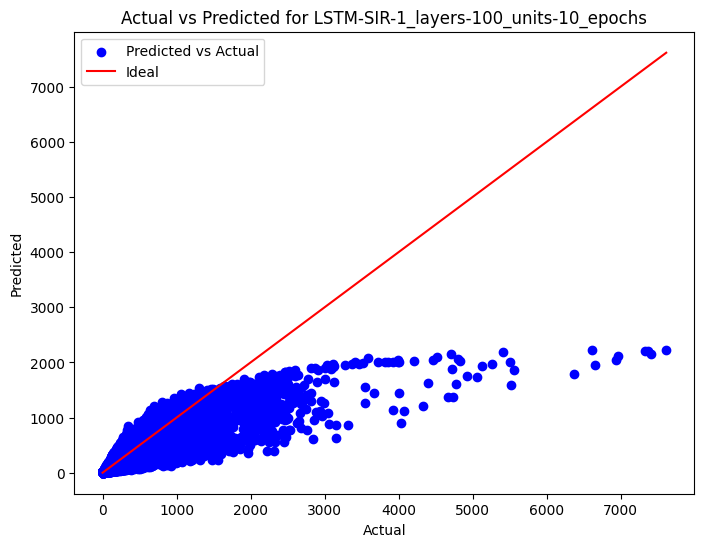

In [ ]:
# Now, we can load the best model and plot its scatter
def plot_best_model_scatter(model_name, test_data_scaled, look_back, scalers):
    # Load the best model
    model = load_model(f'{model_name}/model_{model_name}.keras')

    # Make predictions for the entire test set
    predicted_series_list = []
    actual_series_list = []

    for i in range(test_data_scaled.shape[1]):
        test_series = test_data_scaled[:, i]
        X_test_i, y_test_i = create_sequences(test_series, look_back)
        X_test_i = X_test_i.reshape((X_test_i.shape[0], look_back, 1))

        # Predict
        predicted_test_i = model.predict(X_test_i)
        predicted_test_i_inverse = scalers[0].inverse_transform(predicted_test_i.reshape(-1, 1))
        y_test_i_inverse = scalers[0].inverse_transform(y_test_i.reshape(-1, 1))

        predicted_series_list.append(predicted_test_i_inverse)
        actual_series_list.append(y_test_i_inverse)

    # Flatten the predictions and actual values for scatter plotting
    predicted_flat = np.concatenate(predicted_series_list)
    actual_flat = np.concatenate(actual_series_list)

    # Plot the scatter plot for actual vs predicted
    plt.figure(figsize=(8, 6))
    plt.scatter(actual_flat, predicted_flat, color='blue', label='Predicted vs Actual')
    plt.plot([actual_flat.min(), actual_flat.max()], [actual_flat.min(), actual_flat.max()], color='red', label='Ideal')
    plt.title(f'Actual vs Predicted for {model_name}')
    plt.xlabel('Actual')
    plt.ylabel('Predicted')
    plt.legend()
    plt.show()

# Plot scatter for the best model
plot_best_model_scatter(best_model_name, test_data_scaled, look_back, scalers)